# Lab 9: Gyroscope parameters

Adhambek Yashnarbekov, ID 240062

The robot only logs the data, and all calculations are done here. I chose Option A: the robot spins in place, sending power `u` to the right wheel (M3) and `-u` to the left wheel (M4).

The program sequence is as follows:
1. A 2-minute warm-up run without saving any logs.
2. A 3-minute resting period (`static`).
3. 36 seconds of sine-wave rotation (`sin`) and 36 seconds of square-wave rotation (`rect`). These have a 4-second period and amplitudes of 30% → 60% → 150% (each lasting 12 seconds, capped at 100%).
4. A 3-second resting period at the end (`rest`).

On the robot, I ran `lab9_gyro.js` because the instructions ask to use `readRawData()`, which cannot be accessed using TRIK Studio blocks (the standard block variable only uses `read()`). The file `lab9_gyro.qrs` is the exact same program built with blocks (logging `gyroscope[2]` and `gyroscope[3]`), which I verified in the 2D simulator.

Columns in `lab9_gyro.csv` are:
* `t_us` = `read()[3]`
* `gz_cal` = `read()[2]` (calibrated rate in mdeg/s)
* `encL` = Left encoder (E4)
* `encR` = Right encoder (E3)
* `gz_raw` = `readRawData()[2]` (raw rate)
* `u` = Motor command / power
* `t_ms` = Program clock time
* `phase` = Phase of the run

Please upload `lab9_gyro.csv` in the next cell.

In [35]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import pandas as pd                 # table work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select lab9_gyro.csv

Saving lab9_gyro.qrs to lab9_gyro.qrs


If the file uploaded above is too small (under 100 bytes), your CSV file might be empty. Please run the cell below to re-upload the complete `lab9_gyro.csv` file from your computer.

## Data and time adjustments

In [36]:
log = pd.read_csv('lab9_gyro.csv')

# how long is one unit of the gyroscope time stamp: compare it with the program clock t_ms
unit = np.polyfit(log.t_us - log.t_us[0], log.t_ms - log.t_ms[0], 1)[0]
print(f'one unit of t_us = {unit:.4f} ms')

repeated = (log.t_us.diff() == 0).sum()
log = log[log.t_us.diff() != 0].reset_index(drop=True)   # the same gyro sample read twice: keep one
print(f'{repeated} repeated gyro samples removed')

log['t'] = (log.t_us - log.t_us[0]) * 0.256 / 1000        # time of the gyro sample, s
log['gz'] = log.gz_cal / 1000                             # deg/s

static = log[log.phase == 'static'].copy()
turn = log[log.phase != 'static'].copy()                  # sin, rect and 3 s of rest
static['t'] -= static.t.iloc[0]
turn['t'] -= turn.t.iloc[0]

for name in ['static', 'sin', 'rect', 'rest']:
    part = log[log.phase == name]
    print(f'{name:7s} {len(part):5d} samples, {part.t.iloc[-1] - part.t.iloc[0]:6.1f} s, one sample every {1000 * part.t.diff().mean():.0f} ms')

one unit of t_us = 0.2560 ms
10 repeated gyro samples removed
static   3890 samples,  180.0 s, one sample every 46 ms
sin       551 samples,   36.1 s, one sample every 66 ms
rect      553 samples,   36.0 s, one sample every 65 ms
rest       65 samples,    3.0 s, one sample every 46 ms


The instructions state that `t_us` is in microseconds (ͳs). However, comparing it to the system clock `t_ms`, one unit of `t_us` actually equals 0.256 ms. Therefore, the actual time of each sample is calculated as `t_us`  0.256 ms.

Even though the pause in the program loop is set to 10 ms, a single cycle takes about 46 ms when the robot is still, and about 65 ms when the motors are running. This delay happens because every loop reads the gyroscope twice (`read` and `readRawData`) and reads both encoders, which adds about 36 ms of execution time (similar to the 45 ms delay observed in Lab 7).

Because of this, the log records about 22 samples per second when resting and 15 samples per second when rotating, instead of the targeted 100. We will use the actual timestamps for all integration steps below.

## 1. Gyroscope Offset $b_0$

The offset is the average value reported by the gyroscope when the robot is completely still. The lab guidelines suggest using the average of the first 30 seconds as the baseline offset.

This code performs gyroscope static bias (zero-rate offset) calibration and stability analysis using sensor data stored in a pandas DataFrame named static.


b0 = 1.053 deg/s, standard error 0.003 deg/s, N = 646
first  1 s: b0 = 1.026 deg/s
first  2 s: b0 = 1.008 deg/s
first  5 s: b0 = 1.028 deg/s
first 10 s: b0 = 1.065 deg/s
first 20 s: b0 = 1.068 deg/s
first 30 s: b0 = 1.053 deg/s


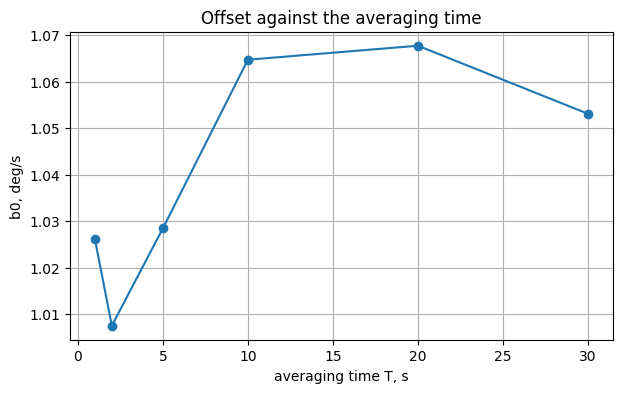

In [37]:
def integrate(w, t):
    # trapezoid rule with the real time stamps
    w = np.array(w); t = np.array(t)
    return np.concatenate([[0], np.cumsum((w[1:] + w[:-1]) / 2 * np.diff(t))])

first30 = static[static.t < 30]
b0 = first30.gz.mean()
se = first30.gz.std() / np.sqrt(len(first30))
print(f'b0 = {b0:.3f} deg/s, standard error {se:.3f} deg/s, N = {len(first30)}')

T_list = [1, 2, 5, 10, 20, 30]
b0_T = [static.gz[static.t < T].mean() for T in T_list]
for T, b in zip(T_list, b0_T):
    print(f'first {T:2d} s: b0 = {b:.3f} deg/s')

plt.figure(figsize=(7, 4))
plt.plot(T_list, b0_T, 'o-')
plt.xlabel('averaging time T, s'); plt.ylabel('b0, deg/s'); plt.grid(True)
plt.title('Offset against the averaging time')
plt.show()

Our calculated baseline offset is $b_0$ = 1.053  0.003 deg/s. Looking at the plot, the offset value shifts by about 0.02 to 0.04 deg/s between 1, 2, 5, and 10 seconds, but stays stable within 0.015 deg/s from 10 seconds onward (values: 1.065, 1.068, 1.053). This shows that averaging for about 10 seconds is plenty of time to get a reliable calibration.

My calibration method:
The function `calibrate_gyro(log)` takes a recording of the stationary robot and returns the median value of the first 10 seconds. We use the median instead of the mean to prevent any sudden spikes or noise from shifting the result. We choose 10 seconds because the curve of $b_0(T)$ flattens out and becomes stable at this point.

This part of the code (below) builds a practical calibration function using what was learned in the first snippet, and then tests how well it actually prevents heading drift over time.

In [38]:
def calibrate_gyro(log, T=10):
    # log: gyro log while the robot stands still; returns b0 in deg/s
    part = log[log.t - log.t.iloc[0] < T]      # the first T seconds of this log
    return np.median(part.gz)                  # median: one bumped sample does not move it

b0_mine = calibrate_gyro(static)
print(f'my b0 from the first 10 s of the static log = {b0_mine:.3f} deg/s')

after = static[static.t >= 10]                 # what is left after these 10 s
left = integrate(after.gz - b0_mine, after.t)
for T in [60, 120, 170]:
    i = np.searchsorted(after.t - 10, T) - 1
    print(f'{T:3d} s after the calibration the heading error is {left[i]:.1f} deg')

my b0 from the first 10 s of the static log = 1.058 deg/s
 60 s after the calibration the heading error is -1.8 deg
120 s after the calibration the heading error is -5.1 deg
170 s after the calibration the heading error is -10.0 deg


Using this 10-second calibration, my offset $b_0$ is 1.058 deg/s. With this calibration, the accumulated heading error while standing still is -1.8 in 1 minute, -5.1 in 2 minutes, and -10.0 over 170 seconds (the rest of the stationary log). This error grows because the actual sensor offset slowly drifts downward over time (as shown in Section 2). Therefore, the calibration should always be performed right before starting a run.

## 2. Bias drift $d$

Here we analyze how the gyroscope offset changes during the 3 minutes of rest and how this drift affects our calculated heading.


This part investigates why subtracting a single constant bias b0 still leaves residual heading error over time: the gyroscope's bias isn't truly constant—it drifts linearly over time (often due to sensor self-heating after power-on).

30-s window means, deg/s: [1.053 1.012 1.038 0.993 0.97  0.951]
d = -0.039 deg/s per min
(a) heading drift of the raw rate: 60.2 deg/min, b0 * 60 = 63.2 deg/min
(b) heading error after 1 min with b0 subtracted: -1.3 deg
(b) heading error after 2 min with b0 subtracted: -3.5 deg
(b) heading error after 3 min with b0 subtracted: -9.1 deg


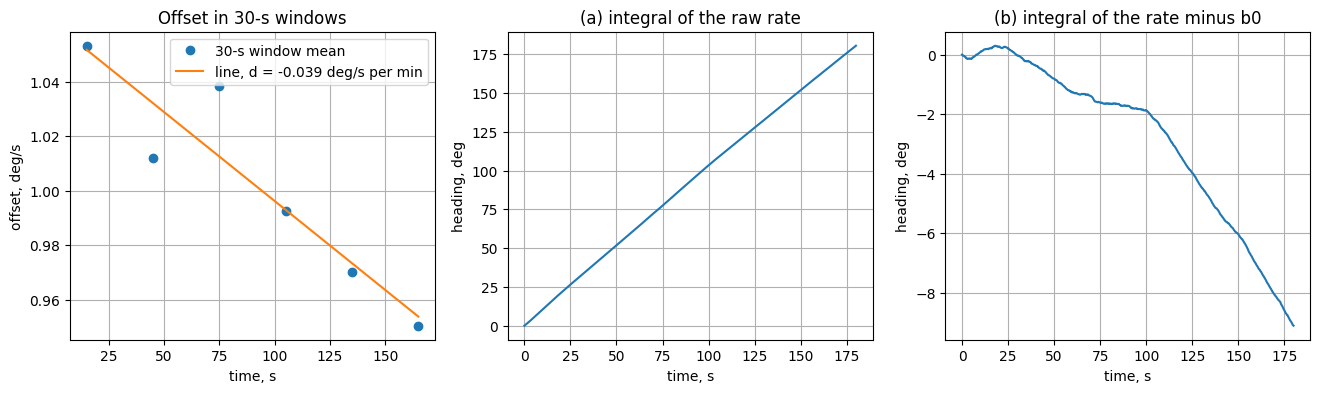

In [39]:
centres, means = [], []
for a in range(0, 180, 30):                          # 30-s windows
    w = static[(static.t >= a) & (static.t < a + 30)]
    centres.append(a + 15); means.append(w.gz.mean())
line = np.polyfit(centres, means, 1)
d = line[0]                                          # deg/s per s
print('30-s window means, deg/s:', np.round(means, 3))
print(f'd = {d * 60:.3f} deg/s per min')

theta_raw = integrate(static.gz, static.t)           # (a) raw rate
theta_cor = integrate(static.gz - b0, static.t)      # (b) rate minus b0
slope = np.polyfit(static.t, theta_raw, 1)[0] * 60
print(f'(a) heading drift of the raw rate: {slope:.1f} deg/min, b0 * 60 = {b0 * 60:.1f} deg/min')
for T in [60, 120, 180]:
    i = np.searchsorted(static.t, T) - 1
    print(f'(b) heading error after {T // 60} min with b0 subtracted: {theta_cor[i]:.1f} deg')

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].plot(centres, means, 'o', label='30-s window mean')
axs[0].plot(centres, np.polyval(line, centres), label=f'line, d = {d * 60:.3f} deg/s per min')
axs[0].set_xlabel('time, s'); axs[0].set_ylabel('offset, deg/s'); axs[0].set_title('Offset in 30-s windows')
axs[1].plot(static.t, theta_raw)
axs[1].set_xlabel('time, s'); axs[1].set_ylabel('heading, deg'); axs[1].set_title('(a) integral of the raw rate')
axs[2].plot(static.t, theta_cor)
axs[2].set_xlabel('time, s'); axs[2].set_ylabel('heading, deg'); axs[2].set_title('(b) integral of the rate minus b0')
axs[0].legend()
for ax in axs: ax.grid(True)
plt.show()

The average offset in each 30-second window drops gradually from 1.053 to 0.951 deg/s. Fitting a straight line to these values gives a drift rate of $d$ = -0.039 deg/s per minute.

(a) The integrated heading from the raw sensor data grows almost linearly at a rate of 60.2 deg/min. This is slightly lower than the estimated $b_0 \cdot 60$ = 63.2 deg/min. This happens because $b_0$ is calculated from the first 30 seconds, and the offset decreases later in the run.

(b) When we subtract the initial offset $b_0$, the heading error is -1.3 after 1 minute, -3.5 after 2 minutes, and -9.1 after 3 minutes. The error grows faster over time because the difference between the true offset and our fixed $b_0$ increases as time passes.

## Rotation run: gyro angle and encoder angle

The gyroscope angle $\theta_{gyro}$ is calculated by integrating the calibrated rate `gz` after subtracting the offset $b_0$.

The encoder angle is calculated as $\theta_{enc} = \frac{r}{L}(\varphi_R - \varphi_L)$, using a wheel radius of r = 3.75 cm and a track width of L = 19.4 cm (the same values used in Lab 7).

To find the rotation rate from the encoders, we calculate the slope of $\theta_{enc}$ over a 5-sample window. The vertical gray lines on the plots mark the 12-second intervals when the motor power steps up.

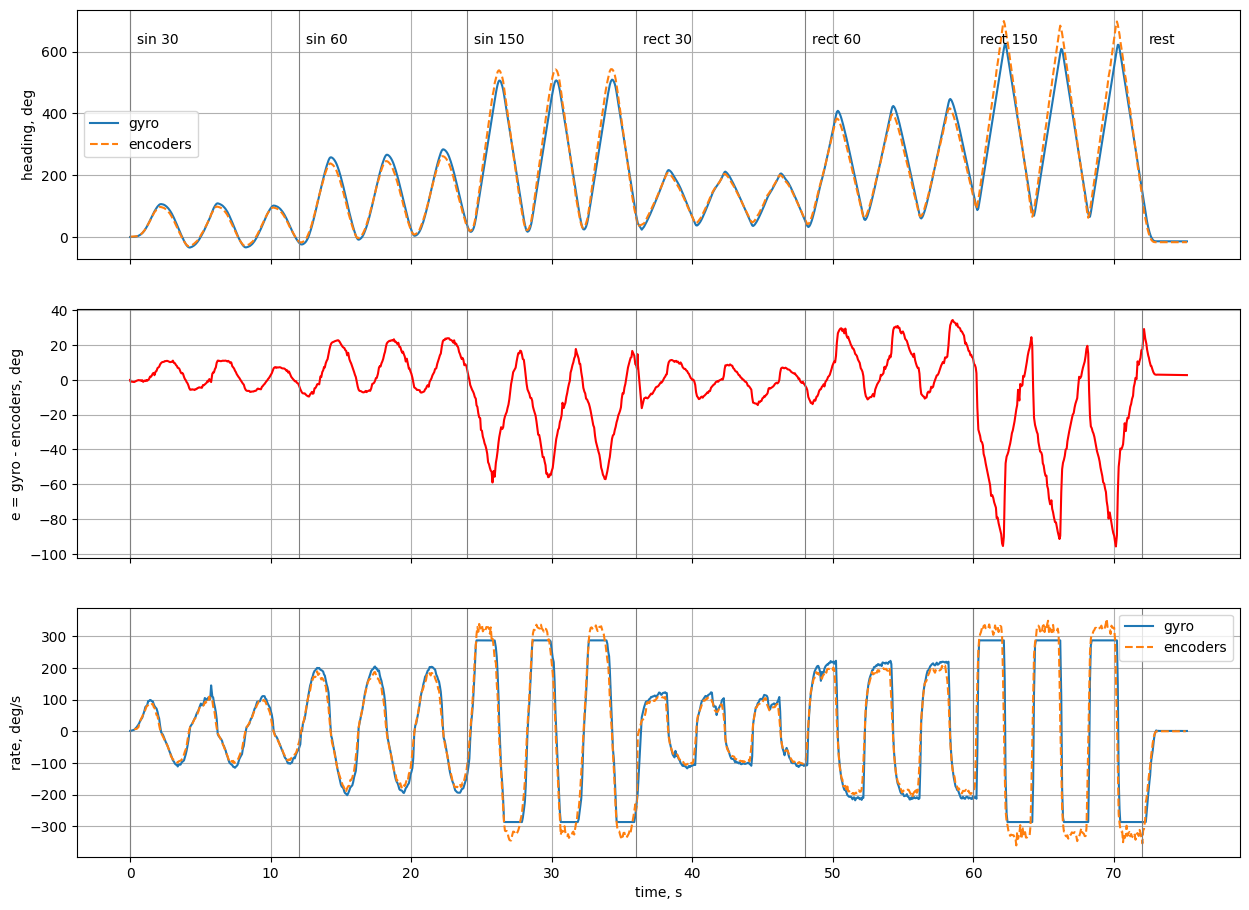

at the end: gyro -14.1 deg, encoders -16.8 deg, e = 2.7 deg
largest |e| during the run: 96 deg


In [40]:
r, L = 3.75, 19.4                                    # cm, wheel radius and track from Lab 5

theta_gyro = integrate(turn.gz - b0, turn.t)         # deg
enc = (turn.encR - turn.encR.iloc[0]) - (turn.encL - turn.encL.iloc[0])
theta_enc = r / L * enc.values                       # deg, the encoders are in degrees
e = theta_gyro - theta_enc

# rate from the encoders: slope of theta_enc over 5 samples
tt = turn.t.values
w_enc = np.full(len(tt), np.nan)
w_enc[2:-2] = (theta_enc[4:] - theta_enc[:-4]) / (tt[4:] - tt[:-4])

names = ['sin 30', 'sin 60', 'sin 150', 'rect 30', 'rect 60', 'rect 150', 'rest']
fig, axs = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
axs[0].plot(tt, theta_gyro, label='gyro')
axs[0].plot(tt, theta_enc, '--', label='encoders')
axs[0].set_ylabel('heading, deg'); axs[0].legend()
axs[1].plot(tt, e, 'r')
axs[1].set_ylabel('e = gyro - encoders, deg')
axs[2].plot(tt, turn.gz, label='gyro')
axs[2].plot(tt, w_enc, '--', label='encoders')
axs[2].set_ylabel('rate, deg/s'); axs[2].set_xlabel('time, s'); axs[2].legend()
for ax in axs:
    ax.grid(True)
    for i in range(7):
        ax.axvline(12 * i, color='gray', lw=0.8)
for i, name in enumerate(names):
    axs[0].text(12 * i + 0.5, axs[0].get_ylim()[1] * 0.85, name)
plt.show()

print(f'at the end: gyro {theta_gyro[-1]:.1f} deg, encoders {theta_enc[-1]:.1f} deg, e = {e[-1]:.1f} deg')
print(f'largest |e| during the run: {np.abs(e).max():.0f} deg')

The two calculated angles match closely in shape and magnitude. This confirms that the gyroscope outputs positive values for counter-clockwise rotation (just like the encoders) and that the encoder values are recorded in degrees, not raw ticks.

Analyzing where the tracking error $e(t)$ increases:
* **At 30% and 60% power:** The error $e$ increases during counter-clockwise turns and decreases during clockwise turns. This error is about 9% of the total turned angle, which points to a scale factor error (explained in Section 6).
* **At 150% power:** The gyroscope hits its measurement limit while the encoders show that the robot is spinning much faster. During these rapid turns, the gyroscope misses up to 60 (during sine waves) and 95 (during square waves) of rotation in one direction, then recovers it on the way back. This is due to sensor saturation (explained in Section 3).
* **Wheel slip:** There are no obvious sudden jumps caused by wheel slip. During the sharp steps of the square wave (`rect`), the slopes match those of the smooth sine wave (`sin`).
* **Offset drift:** The error caused by the drifting offset is masked by these large rotational swings, but we will examine it at the very end of the notebook.

By the end of the run, the gyroscope shows a rotation of -14.1, while the encoders show -16.8.

## 3. Measurement range $\omega_{max}$

The fastest rotations occur at 150% amplitude, where the motors run at full limit (100% power).

This snippet diagnoses gyroscope saturation (clipping)—the exact culprit behind why theta_gyro and theta_enc diverged during the fast turns in the previous plot.

limits: +286.7 and -286.4 deg/s (raw 32764 and -32736)
292 of 1169 samples are at the limit
encoder rate in these samples: up to +354 and -360 deg/s


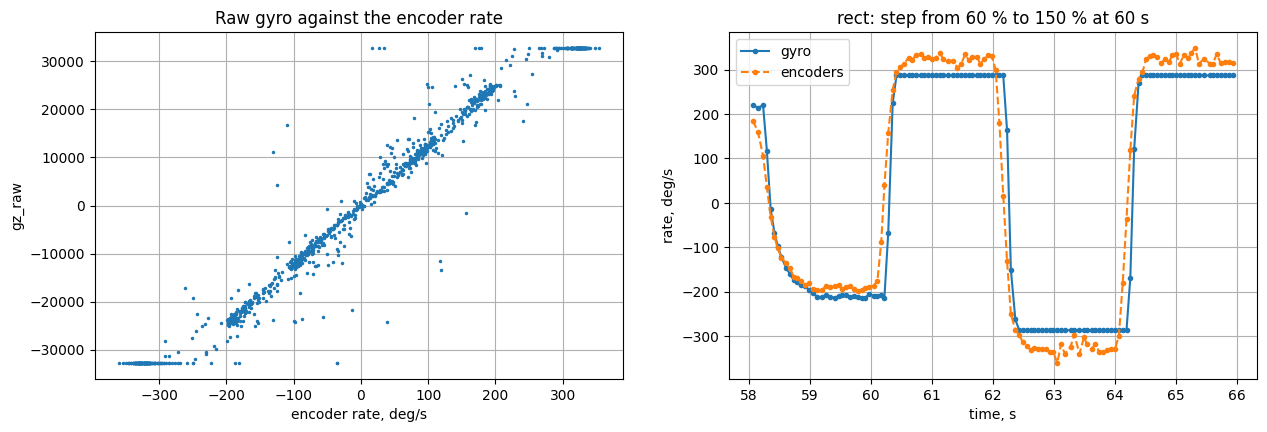

In [41]:
sat = (turn.gz_raw.abs() > 32700).values             # samples at the limit
print(f'limits: +{turn.gz.max():.1f} and {turn.gz.min():.1f} deg/s (raw {turn.gz_raw.max()} and {turn.gz_raw.min()})')
print(f'{sat.sum()} of {len(turn)} samples are at the limit')
print(f'encoder rate in these samples: up to +{np.nanmax(w_enc[sat]):.0f} and {np.nanmin(w_enc[sat]):.0f} deg/s')

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].plot(w_enc, turn.gz_raw, '.', ms=3)
axs[0].set_xlabel('encoder rate, deg/s'); axs[0].set_ylabel('gz_raw'); axs[0].set_title('Raw gyro against the encoder rate')
zoom = (tt > 58) & (tt < 66)
axs[1].plot(tt[zoom], turn.gz[zoom], '.-', label='gyro')
axs[1].plot(tt[zoom], w_enc[zoom], '.--', label='encoders')
axs[1].set_xlabel('time, s'); axs[1].set_ylabel('rate, deg/s'); axs[1].set_title('rect: step from 60 % to 150 % at 60 s'); axs[1].legend()
for ax in axs: ax.grid(True)
plt.show()

The gyroscope limits its output at +286.7 and -286.4 deg/s (corresponding to raw values of 32764 and -32736, which are near the limits of a 16-bit signed integer). Meanwhile, the wheel encoders show actual rotation rates reaching up to +354 and -360 deg/s. This clipping appears as flat lines at the peaks in both plots.

Since 292 out of 1169 samples during the rotation run hit this limit, the robot easily saturates the sensor using its own motors at 100% power, meaning we do not need to spin it by hand to test this limit.

## 4. Resolution $\Delta$

The resolution represents the smallest change in the gyroscope output while the robot is completely still.

In [42]:
big = ~sat & (turn.gz_raw.abs() > 50).values                  # rotation, not at the limit
k_raw = np.median(turn.gz_cal[big] / turn.gz_raw[big]) / 1000  # deg/s per raw unit, the plot is in section 6
raw_values = np.sort(static.gz_raw.unique())
step = np.diff(raw_values).min()
print(f'{len(raw_values)} different raw values at rest, from {raw_values[0]} to {raw_values[-1]}, smallest step {step}')
print(f'delta = {step} * {k_raw:.5f} = {step * k_raw:.5f} deg/s')
print('steps of gz_cal at rest, mdeg/s:', np.unique(np.diff(np.sort(static.gz_cal.unique())))[:2])

60 different raw values at rest, from 86 to 145, smallest step 1
delta = 1 * 0.00875 = 0.00875 deg/s
steps of gz_cal at rest, mdeg/s: [8 9]


At rest, the raw gyroscope signal outputs 60 different values between 86 and 145, changing in steps of exactly 1 raw unit. This gives us a resolution of $\Delta$ = 1 unit = 0.00875 deg/s (using the scale factor calculated in Section 6). The calibrated output `gz_cal` changes in steps of 8 or 9 mdeg/s because it represents the raw value multiplied by 8.75 and rounded to the nearest integer.

## 5. Noise standard deviation $\sigma$

We analyze the noise using the 3-minute resting log with the baseline offset $b_0$ subtracted.

This part of the code  analyzes the statistical distribution of the gyroscope's measurement noise at rest—specifically checking whether the sensor noise behaves like an ideal Gaussian (normal) white noise process or contains outliers/heavy tails.

sigma = 0.079 deg/s, mean of the noise -0.050 deg/s
12 of 3890 samples are more than 3 sigma from the mean (0.31 %, a Gaussian gives 0.27 %)
smallest -0.33, largest 0.21 deg/s


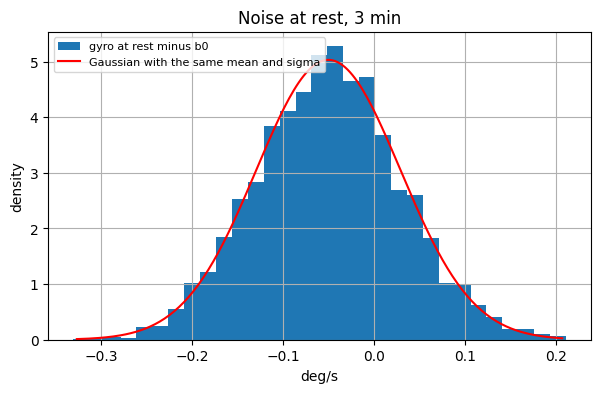

In [43]:
noise = static.gz - b0
sigma = noise.std()
far = (np.abs(noise - noise.mean()) > 3 * sigma).sum()
print(f'sigma = {sigma:.3f} deg/s, mean of the noise {noise.mean():.3f} deg/s')
print(f'{far} of {len(noise)} samples are more than 3 sigma from the mean ({100 * far / len(noise):.2f} %, a Gaussian gives 0.27 %)')
print(f'smallest {noise.min():.2f}, largest {noise.max():.2f} deg/s')

x = np.linspace(noise.min(), noise.max(), 200)
gauss = np.exp(-(x - noise.mean()) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))
plt.figure(figsize=(7, 4))
bins = np.arange(noise.min() - step * k_raw / 2, noise.max() + 2 * step * k_raw, 2 * step * k_raw)   # 2 raw units wide
plt.hist(noise, bins=bins, density=True, label='gyro at rest minus b0')
plt.plot(x, gauss, 'r', label='Gaussian with the same mean and sigma')
plt.xlabel('deg/s'); plt.ylabel('density'); plt.grid(True); plt.legend(loc='upper left', fontsize=8)
plt.title('Noise at rest, 3 min')
plt.show()

The noise standard deviation is $\sigma$ = 0.079 deg/s. The histogram matches a standard Gaussian distribution: only 12 out of 3890 samples (0.31%) fall outside the 3ͳ limit (compared to 0.27% expected in a perfect Gaussian curve). There are no unusual noise spikes, and all readings stay between -0.33 and +0.21 deg/s.

The average noise is slightly offset from zero (-0.050 deg/s) because $b_0$ is based on the first 30 seconds of the log, and the sensor offset drifts downward over the rest of the 3 minutes. Note that this value of $\sigma$ is specific to our sample rate of about 22 samples per second.

## 6. Scale factor $s$

A single 'swing' is defined as the interval where the motor command keeps the same direction, causing the robot to rotate one way. For each swing, we fit a straight line comparing the integrated gyro angle $\theta_{gyro}$ against the encoder angle $\theta_{enc}$. The slope of this line represents $1 + s$. We calculate and average the scale factors for counter-clockwise (CCW) and clockwise (CW) directions separately.

This code below performs a three-part audit of the gyroscope's axis orientation, unit conversion factor, and scale-factor accuracy against the wheel encoders during the dynamic turn test (turn).

correlation of the gyro rate and the encoder rate: 0.978
raw -> deg/s: 0.00875 deg/s per raw unit (8.75 mdeg/s); gz_cal = 8.75 * gz_raw exactly in 246 of 877 rows
sin 30    s =   +7.8 % CCW,  +10.0 % CW
sin 60    s =   +8.3 % CCW,   +8.2 % CW
sin 150   s =  -10.5 % CCW,   -9.7 % CW
rect 30   s =   +9.6 % CCW,   +9.0 % CW
rect 60   s =   +8.4 % CCW,   +8.9 % CW
rect 150  s =  -12.1 % CCW,  -12.1 % CW
amplitudes 30 and 60 % together: s = +8.5 % CCW, +9.0 % CW
one line through all points of 30 and 60 %: slope 1.072


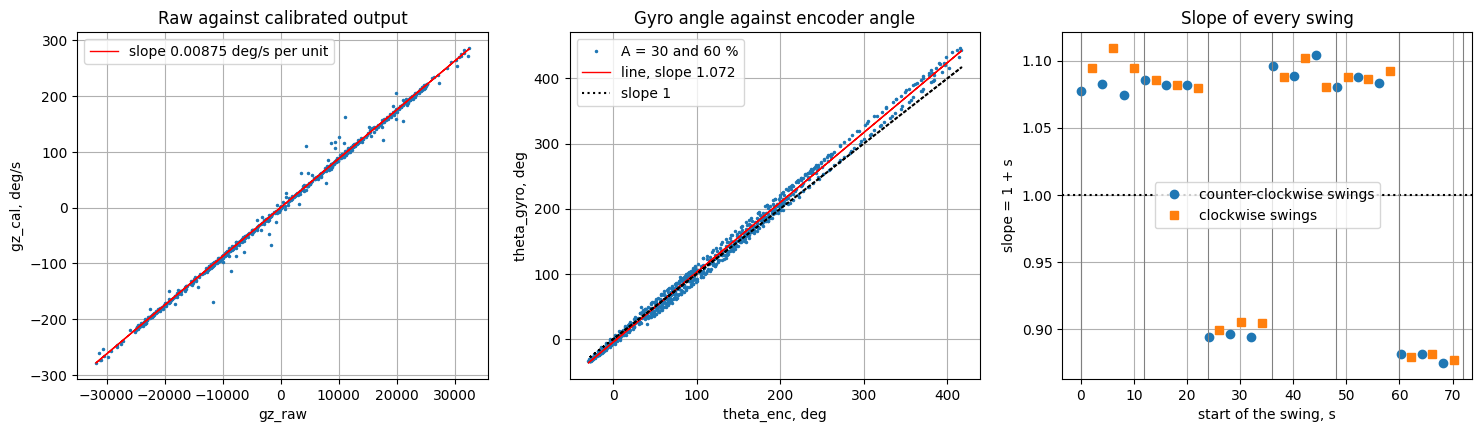

In [44]:
# 1. sign
ok = ~np.isnan(w_enc)
print(f'correlation of the gyro rate and the encoder rate: {np.corrcoef(turn.gz[ok], w_enc[ok])[0, 1]:.3f}')

# 2. raw -> deg/s
same = (np.abs(turn.gz_cal - 8.75 * turn.gz_raw) < 1).values[~sat]
print(f'raw -> deg/s: {k_raw:.5f} deg/s per raw unit ({1000 * k_raw:.2f} mdeg/s); gz_cal = 8.75 * gz_raw exactly in {same.sum()} of {len(same)} rows')

# 3. scale-factor error: a line fit of theta_gyro against theta_enc for every swing
u = turn.u.values
change = np.where(np.diff(np.sign(u)) != 0)[0] + 1        # rows where the motor command changes its sign
starts = np.concatenate([[0], change]); ends = np.concatenate([change, [len(tt)]])
swings = []                                                # start time, direction (+1 CCW, -1 CW), slope
for a, b in zip(starts, ends):
    if u[a] == 0 or b - a < 8:                             # rest or a too short piece
        continue
    part = np.arange(a, b)[tt[a:b] - tt[a] > 0.3]          # skip the first 0.3 s: the robot still turns the old way
    slope = np.polyfit(theta_enc[part], theta_gyro[part], 1)[0]
    swings.append([tt[a], np.sign(u[a]), slope])
swings = np.array(swings)

def s_of(t1, t2):
    # mean s in % of the swings that start between t1 and t2: counter-clockwise and clockwise
    m = (swings[:, 0] >= t1 - 0.2) & (swings[:, 0] < t2 - 0.2)
    return 100 * (swings[m & (swings[:, 1] > 0), 2].mean() - 1), 100 * (swings[m & (swings[:, 1] < 0), 2].mean() - 1)

for i, name in enumerate(names[:6]):
    a, b = s_of(12 * i, 12 * i + 12)
    print(f'{name:9s} s = {a:+6.1f} % CCW, {b:+6.1f} % CW')
slow_sw = (swings[:, 0] < 23.8) | ((swings[:, 0] > 35.8) & (swings[:, 0] < 59.8))    # amplitudes 30 and 60 %
s_ccw = 100 * (swings[slow_sw & (swings[:, 1] > 0), 2].mean() - 1)
s_cw = 100 * (swings[slow_sw & (swings[:, 1] < 0), 2].mean() - 1)
print(f'amplitudes 30 and 60 % together: s = {s_ccw:+.1f} % CCW, {s_cw:+.1f} % CW')
s = (s_ccw + s_cw) / 200

slow = (tt < 24) | ((tt > 36) & (tt < 60))
fit = np.polyfit(theta_enc[slow], theta_gyro[slow], 1)
print(f'one line through all points of 30 and 60 %: slope {fit[0]:.3f}')

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
axs[0].plot(turn.gz_raw[~sat], turn.gz_cal[~sat] / 1000, '.', ms=3)
axs[0].plot(turn.gz_raw[~sat], k_raw * turn.gz_raw[~sat], 'r', lw=1, label=f'slope {k_raw:.5f} deg/s per unit')
axs[0].set_xlabel('gz_raw'); axs[0].set_ylabel('gz_cal, deg/s'); axs[0].set_title('Raw against calibrated output'); axs[0].legend()
axs[1].plot(theta_enc[slow], theta_gyro[slow], '.', ms=3, label='A = 30 and 60 %')
axs[1].plot(theta_enc[slow], np.polyval(fit, theta_enc[slow]), 'r', lw=1, label=f'line, slope {fit[0]:.3f}')
axs[1].plot(theta_enc[slow], theta_enc[slow], 'k:', label='slope 1')
axs[1].set_xlabel('theta_enc, deg'); axs[1].set_ylabel('theta_gyro, deg'); axs[1].set_title('Gyro angle against encoder angle'); axs[1].legend()
ccw = swings[:, 1] > 0
axs[2].plot(swings[ccw, 0], swings[ccw, 2], 'o', label='counter-clockwise swings')
axs[2].plot(swings[~ccw, 0], swings[~ccw, 2], 's', label='clockwise swings')
axs[2].axhline(1, color='k', ls=':')
for i in range(7):
    axs[2].axvline(12 * i, color='gray', lw=0.8)
axs[2].set_xlabel('start of the swing, s'); axs[2].set_ylabel('slope = 1 + s'); axs[2].set_title('Slope of every swing'); axs[2].legend()
for ax in axs: ax.grid(True)
plt.show()

1. **Direction and Sign:** The gyroscope rate correlates highly with the encoder rate (correlation is 0.98). This confirms that a positive `gz` value indicates counter-clockwise rotation, matching the direction of $\theta_{enc}$.
2. **Raw to Physical Units Conversion:** The calibrated values follow `gz_cal` = 8.75  `gz_raw` in mdeg/s (or 0.00875 deg/s per raw unit). The slight deviations from this line happen when `read()` and `readRawData()` return two different updates within the same loop cycle. Since we did not run the built-in `calibrate()` function, the calibrated reading has the exact same baseline offset as the raw reading.
3. **Scale Factor at Moderate Speeds:** At 30% and 60% power amplitudes, the slopes of the swings range between 1.07 and 1.11, yielding a scale-factor error $s$ of +8.5% for counter-clockwise and +9.0% for clockwise turns. The gyroscope measures about 9% more rotation than the wheel encoders, and this error is nearly symmetric in both directions.
4. **Speed Independence:** Below the sensor's saturation limit, the scale factor remains constant regardless of speed. The testing phases (sin 30, sin 60, rect 30, and rect 60) all result in a scale factor error of 8% to 10%. At 150% power, the slope drops significantly to 0.90 (sine wave) and 0.88 (square wave) because of sensor clipping, not because of the scale factor itself.

Since the encoder angle $\theta_{enc}$ depends on the ratio of the wheel radius to the track width (r/L), part of this 9% difference could be caused by small inaccuracies in our measurements of r or L. For instance, using a wheel radius of r = 4.2 cm (as seen in some demos) would change the calculated scale factor error $s$ to approximately -3%.

## Physical alignment check and fresh calibration performance

The instructions suggest using tape markers and a protractor to verify the physical angle of the robot. Since I only had a tape measure, I measured the distance from a nearby wall to the inside edges of both wheels (which are 16.6 cm apart) before and after the test run.

Before the run, both wheels were exactly 39 cm from the wall. After the run, the left wheel was 23 cm away and the right wheel was 19 cm away. We can calculate the actual physical rotation angle using the formula:
`asin(difference_in_distance / distance_between_wheels)` (where positive values represent counter-clockwise rotation).

We will also test a fresh calibration using the final 10 seconds of rest right before the rotation run begins (`b0_last` = 0.953 deg/s).

In [45]:
W = 16.6                         # cm between the two points on the robot (inner edges of the wheels)
before = [39, 39]                # cm from the wall to the left and to the right point
after = [23, 19]
tape = np.degrees(np.arcsin(((after[1] - after[0]) - (before[1] - before[0])) / W))   # + is counter-clockwise

b0_last = calibrate_gyro(static[static.t >= 170])          # my calibration on the last 10 s before the run
theta_mine = integrate(turn.gz - b0_last, turn.t)
still = turn[turn.t > turn.t.iloc[-1] - 2]                 # last 2 s, the robot stands again

print(f'tape                               {tape:6.1f} deg')
print(f'encoders                           {theta_enc[-1]:6.1f} deg')
print(f'gyro, b0 = {b0:.3f} (first 30 s)      {theta_gyro[-1]:6.1f} deg')
print(f'gyro, b0 = {b0_last:.3f} (last 10 s)       {theta_mine[-1]:6.1f} deg')
print(f'gyro at rest after the run: {still.gz.mean():.3f} deg/s')
print(f'rate left with b0 from the first 30 s: {still.gz.mean() - b0:+.3f} deg/s = {60 * (still.gz.mean() - b0):+.1f} deg/min')
print(f'rate left with my b0 from the last 10 s: {still.gz.mean() - b0_last:+.3f} deg/s = {60 * (still.gz.mean() - b0_last):+.1f} deg/min')

tape                                -13.9 deg
encoders                            -16.8 deg
gyro, b0 = 1.053 (first 30 s)       -14.1 deg
gyro, b0 = 0.953 (last 10 s)         -6.6 deg
gyro at rest after the run: 0.924 deg/s
rate left with b0 from the first 30 s: -0.129 deg/s = -7.8 deg/min
rate left with my b0 from the last 10 s: -0.029 deg/s = -1.7 deg/min


According to our physical measurements with the tape, the robot stopped at an angle of -13.9 (with an estimated measurement uncertainty of 3 due to manual tape readings).

Comparing the final headings:
* **Physical Tape Measurement:** -13.9
* **Wheel Encoders:** -16.8
* **Gyroscope (using the 3-minute-old offset $b_0$ = 1.053):** -14.1
* **Gyroscope (using the fresh 10-second offset $b_0$ = 0.953):** -6.6

The difference between the two gyroscope headings (7.5) is entirely caused by the sensor drift over the 3-minute resting period (0.1 deg/s  75 seconds = 7.5).

When the robot is stationary during the final 2 seconds, the gyroscope reads an average rate of 0.924 deg/s. This confirms that the true offset during the rotation run was much closer to 0.95 deg/s than 1.05 deg/s.
* Our fresh calibration leaves a tiny residual drift rate of -0.029 deg/s (-1.7 deg/min).
* The older calibration leaves a much larger drift rate of -0.129 deg/s (-7.8 deg/min).

This demonstrates that using a fresh calibration right before the run is critical. The reason the fresh calibration ends up 7 away from the tape measurement is due to saturation: the robot spent a quarter of the run rotating faster than the sensor's limit. When clipping occurs, the integrated heading loses track of the actual angle turned. Since the physical tape check only measures the final resting position, we cannot easily tell which sensor was more accurate during the slower, unclipped parts of the run.

## Simulated gyroscope model

We implement the simulation model described in the instructions using our calculated parameters: scale factor, initial offset, drift, and noise, followed by sensor clipping (saturation) and resolution rounding. We feed the wheel encoder rate into the simulation as the 'true' physical rate of the robot.

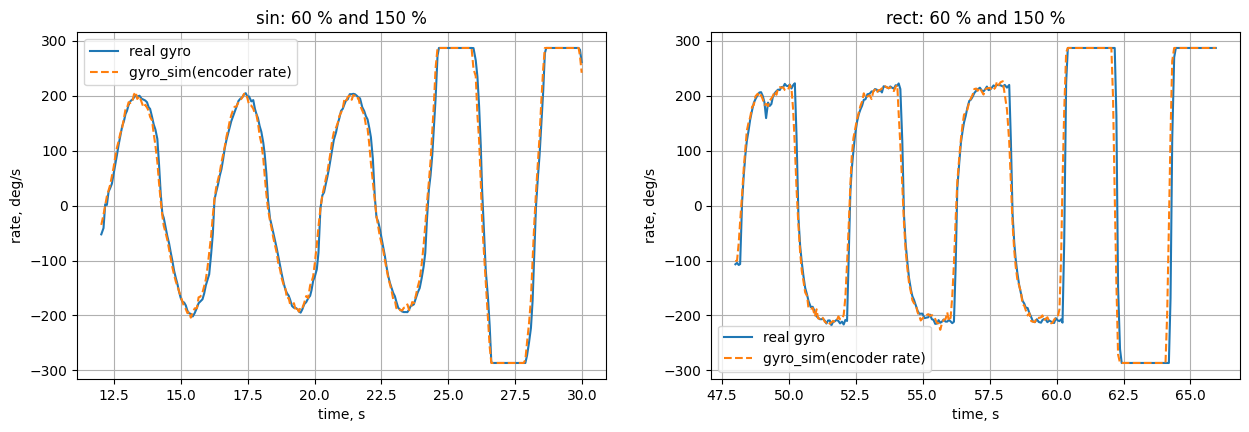

at rest: real mean 1.003, std 0.079; simulated mean 0.996, std 0.086 deg/s


In [46]:
w_max, w_min = turn.gz.max(), turn.gz.min()      # limits, deg/s
delta = step * k_raw                             # resolution, deg/s

def gyro_sim(omega_true, t):
    # model from the README with my parameters; omega_true in deg/s, t in s from the start of the log
    w = (1 + s) * omega_true + b0 + d * t + np.random.normal(0, sigma, len(t))
    w = np.clip(w, w_min, w_max)                 # saturation
    return np.round(w / delta) * delta           # resolution

np.random.seed(1)
gz_sim = gyro_sim(np.nan_to_num(w_enc), tt + 180)    # true rate = encoder rate; the run starts 180 s after the log start

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (a, b) in zip(axs, [(12, 30), (48, 66)]):
    m = (tt > a) & (tt < b)
    ax.plot(tt[m], turn.gz[m], label='real gyro')
    ax.plot(tt[m], gz_sim[m], '--', label='gyro_sim(encoder rate)')
    ax.set_xlabel('time, s'); ax.set_ylabel('rate, deg/s'); ax.grid(True); ax.legend()
axs[0].set_title('sin: 60 % and 150 %'); axs[1].set_title('rect: 60 % and 150 %')
plt.show()

rest_sim = gyro_sim(np.zeros(len(static)), static.t.values)
print(f'at rest: real mean {static.gz.mean():.3f}, std {static.gz.std():.3f}; simulated mean {rest_sim.mean():.3f}, std {rest_sim.std():.3f} deg/s')

The simulated gyroscope matches the real sensor output very closely during slow movements and clips at the exact same limits during rapid turns.

When resting, the real sensor has a mean rate of 1.003 deg/s and a standard deviation of 0.079 deg/s, while the simulated model yields a mean of 0.996 deg/s and a standard deviation of 0.086 deg/s. The simulation's noise is slightly higher because our measured value of $\sigma$ already included a small amount of drift, which the simulation model adds again.

## Gyroscope Parameters Table

| Parameter | Symbol | Value | Unit | Evaluation Method |
|---|---|---|---|---|
| Offset (bias) | $b_0$ | 1.053  0.003 | deg/s | Mean value during resting state, T = 30 s |
| Bias drift | $d$ | -0.039 | deg/s/min | Calculated across 30-s window averages |
| Uncorrected heading drift | | 60.2 | deg/min | Slope of integrated angle ͸(t) at rest |
| Measurement range | $\omega_{max}$ | +286.7 / -286.4 | deg/s | Maximum saturation level at 100% motor power |
| Resolution | $\Delta$ | 0.00875 | deg/s | Quantization size corresponding to 1 raw unit |
| Noise standard deviation | $\sigma$ | 0.079 | deg/s | Standard deviation while resting, 3 min |
| Raw-to-degree conversion factor | | 0.00875 | deg/s per unit | Ratio of `gz_cal` / `gz_raw` |
| Scale-factor error CCW / CW | $s$ | +8.5 / +9.0 | % | Gyroscope vs. encoder angle at 30% and 60% power |
| Positive rotation direction | | CCW | — | Verified in Section 6 |

## Short Analysis

* **Without Calibration:** The sensor offset is the largest source of error. An uncorrected offset of 1.05 deg/s will cause the calculated heading to drift by about 11 in just 10 seconds, 62 in 1 minute, and 180 in 3 minutes, even if the robot is completely stationary.
* **With Baseline Offset Subtracted:** Once the initial offset is removed, the next major issue when resting is the bias drift. This drift introduces an error of -1.3 after 1 minute and -9.1 after 3 minutes, with the error growing quadratically over time. The high-frequency noise is very small: a standard deviation of 0.079 deg/s at 22 samples per second results in a random walk error of only about 0.2 after 3 minutes (calculated as $\sigma\sqrt{\Delta t \cdot t}$).
* **During Rotation:** The scale factor error is the dominant issue during active movement. An error of 9% translates to a 8 error for every quarter-turn (90) the robot makes (assuming this error belongs to the gyroscope and not to inaccuracies in our physical wheel dimensions r/L). During active drives, this becomes the largest source of error within the first 10 seconds. Over 1 to 3 minutes, its impact is comparable to the bias drift, depending on how much the robot rotates.
* **Sensor Saturation:** Saturation causes the most severe errors. When the robot turns faster than 286 deg/s, the sensor clips, causing the integrated heading to lose up to 95 in a single turn. It is critical to keep the robot's turn rate below this threshold.
* **Calibration Recommendation:** The best approach is to keep the robot still for 10 seconds immediately before a run and calculate the median of those samples. We use 10 seconds because the offset stabilization curve flattens out by then, and we use the median to protect against isolated noise spikes. Even with this calibration, the heading will drift by about -1.8 in 1 minute and -10 in 3 minutes because the offset continues to drop by 0.04 deg/s every minute. Performing this calibration right before the run is highly effective: utilizing the final 10 seconds of rest before our test run kept the post-run residual drift rate to just -0.03 deg/s, compared to -0.13 deg/s when using the 3-minute-old calibration.